# Лабораторна робота № 8
## Задача комівояжера генетичним і мурашиним алгоритмами

**Інтелектуальний аналіз та візуалізація даних** · 2 години · 4 бали

---

### Постановка

У ЛР5 ви склали піший маршрут: вокзал → 30 пам'яток вашого міста → вокзал. Для 30 точок точний метод не впорався, і ви
взяли найближчого сусіда з доведенням 2-opt. Тепер керівник питає: **«А генетичний алгоритм чи мурахи, про які всі
говорять, дадуть коротший маршрут? І скільки це коштуватиме?»**

Ви відповісте числами: реалізуєте обидва методи (ключові функції пишете самі), запустите їх чесно — з однаковим
бюджетом і по 10 разів — і порівняєте між собою та з результатом ЛР5 за **якістю** і **обчислювальною вартістю**.

### Що здаєте

1. Цей ноутбук із виконаними комірками (перед здачею — «Restart & Run All»; усі виводи збережені).
2. Карту `lr8_маршрут_NN.html` — маршрути ЛР5, ГА, мурах і найкращий на географічній карті (розділ 3.4).
3. Файл `lr8_результат_NN.json`, який створить остання комірка.

**Без карти і без заповненої декларації про використання ШІ (розділ 6) робота не приймається.**

### Як працювати

- Готовий код просто виконуйте. Комірки **ВАШІ ВІДПОВІДІ / ВАШ КОД** заповнюєте ви; після кожної стоїть перевірка
  `assert` — поки вона не проходить, далі не йдіть.
- Числа у звіті беріть з **власних** виводів. Методичні вказівки — у файлі `ЛР8_методичні_вказівки_студенту.docx`.

| Етап | Розділ | Хв |
|---|---|---|
| Дані і відтворення ЛР5 | 0 | 10 |
| Генетичний алгоритм | 1 | 25 |
| Мурашина система | 2 | 25 |
| Порівняння, гібрид і карта | 3 | 15 |
| Звіт колеги на критику | 4 | 10 |
| Звіт, декларація ШІ і результат | 5–6 | 5 |

**Лопатін Володимир, ШІ-31, варіант 12.** Джерело — власна ЛР5 для Хмельницького.

In [1]:
# Запуск із ядра, де встановлені numpy, pandas, matplotlib, scipy,
# networkx, pyarrow, shapely, folium, xyzservices та ipykernel.
# Перевірено у Python 3.12 із середовищем, використаним для ЛР5.
import importlib.util
packages = ('numpy', 'pandas', 'matplotlib', 'scipy', 'networkx', 'pyarrow', 'shapely', 'folium', 'xyzservices')
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError('Встановіть пакети у ядро: ' + ', '.join(missing))

In [2]:
import os, glob, json, time, math, hashlib, inspect, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 20)
print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__)

python 3.12.16 | numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1


### Готовий код

Функції, які вам **не треба** писати: довжина маршруту, лічильник оцінок, найближчий сусід і 2-opt з ЛР5,
мутація-розворот і «двигуни» двох алгоритмів. Прочитайте їх — ваші функції вони викликатимуть.

**Кодування.** Вокзал має номер 0 і стоїть на початку й у кінці маршруту, тому хромосома (genome) — перестановка
решти точок `1…n−1`. **Оцінка якості** — одне обчислення довжини маршруту; бюджет усіх методів вимірюємо в оцінках.

In [3]:
import time, math
import numpy as np


def tour_length(D, genome):
    """Довжина замкненого маршруту: вокзал 0 → genome → вокзал 0. Матриця може бути несиметричною."""
    t = np.concatenate(([0], genome, [0]))
    return float(D[t[:-1], t[1:]].sum())


class Budget:
    """Лічильник оцінок якості: кожен маршрут, довжину якого обчислили, — одна оцінка."""
    def __init__(self, D, limit):
        self.D, self.limit, self.used = D, limit, 0
        self.best_len, self.best = math.inf, None
        self.curve = []                       # (оцінок, найкраща довжина) — для графіка збіжності
    def left(self):
        return self.limit - self.used
    def f(self, genome):
        self.used += 1
        L = tour_length(self.D, genome)
        if L < self.best_len - 1e-9:
            self.best_len, self.best = L, np.array(genome).copy()
            self.curve.append((self.used, L))
        return L


def nearest_neighbour(D):
    """Як у ЛР5: щоразу йти до найближчої невідвіданої точки."""
    n = len(D); cur = 0; left = set(range(1, n)); g = []
    while left:
        nxt = min(left, key=lambda j: (D[cur, j], j)); g.append(nxt); left.discard(nxt); cur = nxt
    return np.array(g)


def two_opt_lr5(D, genome):
    """2-opt з ЛР5: розвертаємо відрізок і щоразу рахуємо довжину повністю (матриця несиметрична). Повертає маршрут і кількість оцінок."""
    # Як у власній ЛР5: за прохід беремо найкращого сусіда.
    best = list(genome)
    best_len = tour_length(D, best)
    evals = 1
    while True:
        candidate_best, candidate_len = None, best_len
        for i in range(len(best) - 1):
            for j in range(i + 1, len(best)):
                candidate = best[:i] + best[i:j+1][::-1] + best[j+1:]
                length = tour_length(D, candidate)
                evals += 1
                if length < candidate_len - 1e-8:
                    candidate_best, candidate_len = candidate, length
        if candidate_best is None:
            return np.asarray(best), evals
        best, best_len = candidate_best, candidate_len



def reverse_mutation(genome, rng):
    """Мутація-розворот (2-opt): розвернути випадковий відрізок. У несиметричній матриці змінюються не лише два ребра — тому довжину рахуємо повністю."""
    g = genome.copy(); i, k = sorted(rng.choice(len(g), 2, replace=False)); g[i:k + 1] = g[i:k + 1][::-1]
    return g


def run_ga(D, budget, rng, tournament, ox, pop=50, k=2, pm=0.3, elite=2, pc=0.9):
    """Генетичний алгоритм на перестановках. tournament і ox — ваші функції."""
    n = len(D) - 1; B = Budget(D, budget); t0 = time.perf_counter()
    P = [rng.permutation(np.arange(1, n + 1)) for _ in range(pop)]; F = np.array([B.f(g) for g in P])
    while B.left() > 0:
        order = np.argsort(F); Q = [P[i].copy() for i in order[:elite]]; FQ = [F[i] for i in order[:elite]]
        while len(Q) < pop and B.left() > 0:
            a, b = P[tournament(F, k, rng)], P[tournament(F, k, rng)]
            if rng.random() < pc:
                i, j = sorted(rng.choice(n, 2, replace=False)); c = ox(a, b, i, j)
            else:
                c = a.copy()
            if rng.random() < pm:
                c = reverse_mutation(c, rng)
            Q.append(c); FQ.append(B.f(c))
        P, F = Q, np.array(FQ)
    return {'довжина': B.best_len, 'маршрут': B.best, 'оцінок': B.used, 'час_с': time.perf_counter() - t0, 'крива': B.curve}


def run_aco(D, budget, rng, choose_next, update_pheromone, ants=31, alpha=1.0, beta=2.0, rho=0.5, *, nn_length):
    """Мурашина система. choose_next і update_pheromone — ваші функції."""
    n = len(D); B = Budget(D, budget); t0 = time.perf_counter()
    eta = 1.0 / np.maximum(D, 1.0)            # близькість; 1 м замість 0 — щоб не ділити на нуль для «злиплих» точок
    tau = np.full((n, n), ants / nn_length)  # Вже виміряна довжина NN з розділу 0.
    while B.left() > 0:
        tours, lens = [], []
        for _ in range(min(ants, B.left())):
            cur, left, g = 0, list(range(1, n)), []
            while left:
                nxt = choose_next(cur, left, tau, eta, alpha, beta, rng); g.append(nxt); left.remove(nxt); cur = nxt
            g = np.array(g); tours.append(g); lens.append(B.f(g))
        tau = update_pheromone(tau, tours, lens, rho)
    return {'довжина': B.best_len, 'маршрут': B.best, 'оцінок': B.used, 'час_с': time.perf_counter() - t0, 'крива': B.curve}


def mann_whitney(x, y):
    from scipy.stats import mannwhitneyu
    return float(mannwhitneyu(x, y, alternative='two-sided').pvalue)

---
## 0. Ваш варіант і дані

Варіант той самий, що в ЛР5: ваше місто і ваші 31 точка. Покладіть поруч із ноутбуком файл `lr5_результати.json`,
який ви здали в ЛР5, і **теку знімка міста з ЛР5** (`osm_<місто>` з файлами `road_nodes.parquet` і `road_edges.parquet`) —
з неї маршрути на карті підуть вулицями. Якщо ЛР5 у вас немає, ноутбук візьме запасний файл викладача (Львів) — це буде видно
в результаті, і викладач врахує.

In [4]:
from pathlib import Path
STUDENT_NAME = 'Лопатін Володимир'
LIST_NUMBER = 12
HERE = Path.cwd()
if (HERE / 'lab_8').is_dir():
    HERE = HERE / 'lab_8'
LR5_DIR = HERE.parent / 'lab_5'
LR5_FILE = HERE / 'lr5_результати.json'
if not LR5_FILE.is_file():
    LR5_FILE = LR5_DIR / 'lr5_результати.json'

In [5]:
assert STUDENT_NAME and LIST_NUMBER > 0
with LR5_FILE.open(encoding='utf-8') as f:
    LR5 = json.load(f)
SOURCE = 'свої'
assert LR5['номер'] == LIST_NUMBER
BIG = LR5['велика_задача']
raw = BIG.get('матриця_віддалей_м_повна_точність', BIG['матриця_віддалей_м'])
D = np.asarray(raw, dtype=float)
n = len(D)
assert D.shape == (31,31) and np.isfinite(D).all() and (D >= 0).all()
assert np.allclose(D.diagonal(), 0)
NAMES = [p['name'] for p in BIG['точки']]
assert len(NAMES) == n
D_MD5 = hashlib.md5(json.dumps(raw).encode()).hexdigest()[:10]
zeros = int(((D == 0) & ~np.eye(n, dtype=bool)).sum())
asym = float(np.max(np.abs(D - D.T)))
print(f"{LR5['місто']} | варіант {LIST_NUMBER} | {n} точка | контрольна сума {D_MD5}")
print(f'Використано повну точність ЛР5. Максимальна асиметрія {asym:.3g} м, нульових між різними точками {zeros}.')

Хмельницький, Україна | варіант 12 | 31 точка | контрольна сума 0377ba3e8d
Використано повну точність ЛР5. Максимальна асиметрія 6.37e-12 м, нульових між різними точками 0.


### Відтворюємо ЛР5 — і отримуємо базу порівняння

Найближчий сусід + 2-opt детерміновані, тому на вашій матриці мають дати **рівно** ту саму довжину, що в ЛР5.
Заодно міряємо їхній час **на цьому комп'ютері** — порівнювати час можна лише на одній машині.

In [6]:
t0 = time.perf_counter()
NN = nearest_neighbour(D)
L_NN = tour_length(D, NN)
t_nn = time.perf_counter() - t0
t0 = time.perf_counter()
OPT2, EVALS_2OPT = two_opt_lr5(D, NN)
t_2opt = time.perf_counter() - t0
L_2OPT = tour_length(D, OPT2)
LR5_OK = (round(L_NN, 1) == BIG['найближчий_сусід_м'] and
          round(L_2OPT, 1) == BIG['двоопт_м'] and
          [0, *OPT2.tolist(), 0] == BIG['порядок_2opt'])
assert LR5_OK, 'Довжини або порядок не збігаються з власною ЛР5'
print(f'Найближчий сусід: {L_NN:.1f} м | {t_nn:.6f} с')
print(f'2-opt: {L_2OPT:.1f} м | {EVALS_2OPT} оцінок | {t_2opt:.6f} с. Порядок і довжини збіглися з ЛР5.')

Найближчий сусід: 29535.0 м | 0.000918 с
2-opt: 27249.3 м | 3046 оцінок | 0.036172 с. Порядок і довжини збіглися з ЛР5.


---
## 1. Генетичний алгоритм

Цикл (лекція 11, розділ 3): відібрати двох батьків турніром → схрестити OX → іноді мутувати розворотом → оцінити.
Дві найкращі особини переходять у нове покоління без змін (еліта). «Двигун» `run_ga` готовий; ви пишете дві функції.

**1.1. Турнір.** З популяції навмання (з поверненням) беремо `k` особин і повертаємо **індекс** найкоротшої.
`F` — масив довжин маршрутів популяції, `rng` — генератор `np.random.default_rng`.

**1.2. Упорядковане схрещування OX.** Нащадок отримує відрізок `p1[i..j]` (включно) на тих самих позиціях; решту
генів дописуємо в тому порядку, у якому вони йдуть у `p2`, починаючи з позиції `j+1` і по колу, пропускаючи ті,
що вже є, і ставлячи їх на вільні місця теж починаючи з позиції `j+1` по колу. Приклад із лекції:
`p1 = [1 2 3 4 5 6 7 8]`, `p2 = [5 7 1 8 3 6 2 4]`, `i = 2`, `j = 4` → `[1 8 3 4 5 6 2 7]`.

In [7]:
def tournament(F, k, rng):
    """Повертає індекс найкоротшої з k випадкових особин (із поверненням)."""
    candidates = rng.integers(0, len(F), size=k)
    values = np.asarray(F)[candidates]
    return int(candidates[np.argmin(values)])


def ox(p1, p2, i, j):
    """Зберігає відрізок p1[i:j+1], додає гени p2 по колу після j."""
    a, b = np.asarray(p1), np.asarray(p2)
    child = np.empty_like(a)
    child[i:j + 1] = a[i:j + 1]
    retained = set(a[i:j + 1])
    donor_order = np.concatenate((b[j + 1:], b[:j + 1]))
    genes = [gene for gene in donor_order if gene not in retained]
    tail = len(a) - j - 1
    child[j + 1:] = genes[:tail]
    child[:i] = genes[tail:]
    return child

In [8]:
# перевірка ваших функцій
_r = np.random.default_rng(0); _F = np.array([5.0, 1.0, 9.0, 3.0])
assert isinstance(tournament(_F, 2, _r), (int, np.integer)), 'турнір має повертати індекс (ціле число)'
assert tournament(_F, 200, _r) == 1, 'при великому k турнір має майже завжди повертати найкращого'
_freq = np.mean([tournament(_F, 2, _r) == 1 for _ in range(4000)])
assert abs(_freq - (1 - 0.75 ** 2)) < 0.04, 'при k = 2 найкращий має вигравати приблизно в 44 %% випадків, у вас %.0f %%' % (100 * _freq)
_c = ox(np.array([1, 2, 3, 4, 5, 6, 7, 8]), np.array([5, 7, 1, 8, 3, 6, 2, 4]), 2, 4)
assert list(_c) == [1, 8, 3, 4, 5, 6, 2, 7], 'OX на прикладі з лекції дав %s' % list(_c)
for _ in range(200):
    _a, _b = _r.permutation(np.arange(1, 31)), _r.permutation(np.arange(1, 31)); _i, _j = sorted(_r.choice(30, 2, replace=False))
    _c = ox(_a, _b, _i, _j)
    assert sorted(_c) == list(range(1, 31)), 'нащадок OX має бути перестановкою без повторів'
    assert list(_c[_i:_j + 1]) == list(_a[_i:_j + 1]), 'відрізок батька 1 має стояти на тих самих місцях'
GA_TESTS_OK = True
print('обидві функції працюють')

обидві функції працюють


**1.3. Параметри і запуск.** Бюджет — **20 000 оцінок** на запуск, **10 запусків** із сідами 1…10 — однаково для
всіх методів. Типові параметри ГА (лекція 11): популяція 50, турнір 2, еліта 2, схрещування 0,9, мутація 0,3.
Можете змінити `GA_PARAMS` — але спершу подивіться на коротку перевірку двох значень мутації нижче й поясніть свій
вибір у звіті.

In [9]:
BUDGET, RUNS = 20_000, 10
GA_PILOT = {}
for pm in (0.1, 0.3):
    scores = [run_ga(D, BUDGET, np.random.default_rng(100 + s), tournament, ox, pm=pm)['довжина'] for s in range(3)]
    GA_PILOT[pm] = float(np.median(scores))
    print(f'Мутація {pm}: медіана трьох пробних запусків {GA_PILOT[pm]:.1f} м.')

Мутація 0.1: медіана трьох пробних запусків 27592.0 м.


Мутація 0.3: медіана трьох пробних запусків 29967.8 м.


In [10]:
GA_PARAMS = {'pop': 50, 'k': 2, 'pm': min(GA_PILOT, key=GA_PILOT.get), 'elite': 2}
print(GA_PARAMS)

{'pop': 50, 'k': 2, 'pm': 0.1, 'elite': 2}


In [11]:
assert set(GA_PARAMS) == {'pop', 'k', 'pm', 'elite'}
GA = [run_ga(D, BUDGET, np.random.default_rng(s), tournament, ox, **GA_PARAMS) for s in range(1, RUNS + 1)]
print('ГА: медіана %.0f м, найкращий %.0f м, медіанний час %.2f с на запуск' % (np.median([r['довжина'] for r in GA]), min(r['довжина'] for r in GA), np.median([r['час_с'] for r in GA])))

ГА: медіана 27614 м, найкращий 27267 м, медіанний час 1.55 с на запуск


---
## 2. Мурашина система

Кожна «мураха» будує маршрут від вокзалу, обираючи наступну точку з імовірністю (лекція 11, розділ 5)

$$P(i \to j) = \frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l \in \text{невідвідані}} \tau_{il}^{\alpha}\,\eta_{il}^{\beta}}, \qquad \eta_{ij} = \frac{1}{d_{ij}},$$

а після того як усі мурахи ітерації побудували маршрути, феромон випаровується і поповнюється:

$$\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij} + \sum_{k:\,(i \to j) \in T_k} \frac{1}{L(T_k)}.$$

Матриця несиметрична, тож ребро має **напрям**: маршрут, що йде з `i` в `j`, поповнює `tau[i, j]`, а не `tau[j, i]`.
Не забудьте ребра від вокзалу до першої точки і від останньої точки до вокзалу.

**2.1.** `choose_next(cur, left, tau, eta, alpha, beta, rng)` — повертає номер наступної точки зі списку
невідвіданих `left`. **2.2.** `update_pheromone(tau, tours, lens, rho)` — повертає **нову** матрицю феромону;
`tours` — список хромосом (без вокзалу), `lens` — їхні довжини.

In [12]:
def choose_next(cur, left, tau, eta, alpha, beta, rng):
    """Вибирає невідвідану точку з вагою tau**alpha * eta**beta."""
    candidates = np.asarray(left, dtype=np.intp)
    if candidates.size == 1:
        return int(candidates[0])
    weights = np.power(tau[cur, candidates], alpha) * np.power(eta[cur, candidates], beta)
    total = weights.sum()
    probabilities = weights / total if np.isfinite(total) and total > 0 else None
    return int(rng.choice(candidates, p=probabilities))


def update_pheromone(tau, tours, lens, rho):
    """Випаровує феромон і додає 1/L до кожної спрямованої дуги маршруту."""
    updated = np.asarray(tau, dtype=float) * (1 - rho)
    for genome, length in zip(tours, lens, strict=True):
        route = np.concatenate(([0], genome, [0])).astype(np.intp)
        np.add.at(updated, (route[:-1], route[1:]), 1 / length)
    return updated

In [13]:
# перевірка ваших функцій
_r = np.random.default_rng(1); _tau = np.ones((4, 4)); _eta = np.array([[0, 1, 2, 3]] * 4, dtype=float)
_pick = [choose_next(0, [1, 2, 3], _tau, _eta, 1.0, 1.0, _r) for _ in range(6000)]
_fr = [np.mean(np.array(_pick) == j) for j in (1, 2, 3)]
assert all(abs(f - p) < 0.03 for f, p in zip(_fr, [1 / 6, 2 / 6, 3 / 6])), 'частоти вибору %s не відповідають імовірностям 1/6, 2/6, 3/6' % np.round(_fr, 3)
_fr0 = [np.mean(np.array([choose_next(0, [1, 2, 3], _tau, _eta, 1.0, 0.0, _r) for _ in range(3000)]) == j) for j in (1, 2, 3)]
assert all(abs(f - 1 / 3) < 0.04 for f in _fr0), 'при beta = 0 і однаковому феромоні вибір має бути рівноймовірним'
_new = update_pheromone(np.ones((4, 4)), [np.array([1, 2, 3])], [10.0], 0.5)
_exp = np.full((4, 4), 0.5); _exp[[0, 1, 2, 3], [1, 2, 3, 0]] += 0.1
assert _new.shape == (4, 4) and np.allclose(_new, _exp), 'феромон після оновлення не той; очікувалося\n%s' % _exp
ACO_TESTS_OK = True
print('обидві функції працюють')

обидві функції працюють


**2.3. Параметри і запуск.** Типові параметри (лекція 11): мурах стільки, скільки точок, α = 1, β = 2, ρ = 0,5.
Близькість η = 1/d, але для «злиплих» точок з нульовою віддаллю ділимо на 1 м, а не на нуль (див. `run_aco`).
Запуск займе 1–3 хвилини. Спершу коротка перевірка: що буде без близькості (β = 0)?

In [14]:
ACO_PILOT = {}
for beta in (0.0, 2.0):
    scores = [run_aco(D, 3000, np.random.default_rng(200 + s), choose_next, update_pheromone,
                      nn_length=L_NN, beta=beta)['довжина'] for s in range(2)]
    ACO_PILOT[beta] = float(np.median(scores))
    print(f'β={beta:g}: медіана двох запусків з 3000 оцінок {ACO_PILOT[beta]:.1f} м.')

β=0: медіана двох запусків з 3000 оцінок 51679.7 м.


β=2: медіана двох запусків з 3000 оцінок 28269.8 м.


In [15]:
ACO_PARAMS = {'ants': n, 'alpha': 1.0, 'beta': min(ACO_PILOT, key=ACO_PILOT.get), 'rho': 0.5}
print(ACO_PARAMS)

{'ants': 31, 'alpha': 1.0, 'beta': 2.0, 'rho': 0.5}


In [16]:
assert set(ACO_PARAMS) == {'ants', 'alpha', 'beta', 'rho'}
ACO = [run_aco(D, BUDGET, np.random.default_rng(s), choose_next, update_pheromone, nn_length=L_NN, **ACO_PARAMS) for s in range(1, RUNS + 1)]
print('мурахи: медіана %.0f м, найкращий %.0f м, медіанний час %.2f с на запуск' % (np.median([r['довжина'] for r in ACO]), min(r['довжина'] for r in ACO), np.median([r['час_с'] for r in ACO])))

мурахи: медіана 28572 м, найкращий 27387 м, медіанний час 22.62 с на запуск


---
## 3. Порівняння і гібрид

### 3.1. Таблиця: якість і вартість

Розрив рахуємо від **2-opt з ЛР5** (оптимум для 31 точки вам невідомий). Від'ємний розрив — метод **кращий** за ЛР5.

In [17]:
def summary(name, runs):
    L = np.array([r['довжина'] for r in runs]); T = np.array([r['час_с'] for r in runs])
    return {'метод': name, 'медіана, м': round(float(np.median(L))), 'найкращий, м': round(float(L.min())), 'найгірший, м': round(float(L.max())),
            'розрив медіани від 2-opt ЛР5, %': round(100 * (np.median(L) / L_2OPT - 1), 1), 'оцінок': int(np.median([r['оцінок'] for r in runs])),
            'час, с (медіана)': round(float(np.median(T)), 3), 'у скільки разів довше за 2-opt': round(float(np.median(T) / max(t_2opt, 1e-6)))}
TABLE = pd.DataFrame([
    {'метод': 'найближчий сусід (ЛР5)', 'медіана, м': round(L_NN), 'найкращий, м': round(L_NN), 'найгірший, м': round(L_NN), 'розрив медіани від 2-opt ЛР5, %': round(100 * (L_NN / L_2OPT - 1), 1),
     'оцінок': 1, 'час, с (медіана)': round(t_nn, 4), 'у скільки разів довше за 2-opt': round(t_nn / max(t_2opt, 1e-6), 2)},
    {'метод': '2-opt (ЛР5)', 'медіана, м': round(L_2OPT), 'найкращий, м': round(L_2OPT), 'найгірший, м': round(L_2OPT), 'розрив медіани від 2-opt ЛР5, %': 0.0,
     'оцінок': EVALS_2OPT, 'час, с (медіана)': round(t_2opt, 4), 'у скільки разів довше за 2-opt': 1},
    summary('генетичний алгоритм', GA), summary('мурашина система', ACO)]).set_index('метод')
P_GA_ACO = mann_whitney([r['довжина'] for r in GA], [r['довжина'] for r in ACO])
display(TABLE)
print('ГА проти мурах: тест Манна — Вітні, p = %.4f' % P_GA_ACO + (' — різниця значуща' if P_GA_ACO < 0.05 else ' — різниця не доведена'))

,"медіана, м","найкращий, м","найгірший, м","розрив медіани від 2-opt ЛР5, %",оцінок,"час, с (медіана)",у скільки разів довше за 2-opt
метод,,,,,,,
найближчий сусід (ЛР5),29535,29535,29535,8.4,1,0.0009,0.03
2-opt (ЛР5),27249,27249,27249,0.0,3046,0.0362,1.00
генетичний алгоритм,27614,27267,29012,1.3,20000,1.5470,43.00
мурашина система,28572,27387,29752,4.9,20000,22.6170,625.00


ГА проти мурах: тест Манна — Вітні, p = 0.0639 — різниця не доведена


### 3.2. Збіжність

Медіана (з 10 запусків) найкращої довжини залежно від кількості оцінок. Горизонтальні лінії — результати ЛР5.

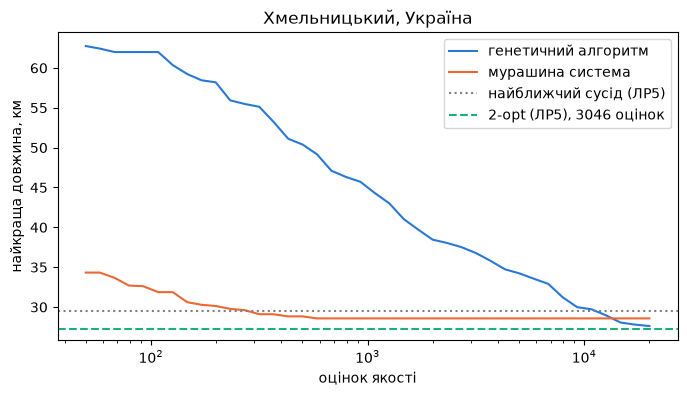

In [18]:
CHECK = np.unique(np.round(np.logspace(np.log10(50), np.log10(BUDGET), 40)).astype(int))
def median_curve(runs):
    out = []
    for c in CHECK:
        vals = [min([L for e, L in r['крива'] if e <= c], default=np.nan) for r in runs]
        out.append(np.nanmedian(vals))
    return out
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(CHECK, np.array(median_curve(GA)) / 1000, label='генетичний алгоритм', color='#2a78d6')
ax.plot(CHECK, np.array(median_curve(ACO)) / 1000, label='мурашина система', color='#eb6834')
ax.axhline(L_NN / 1000, ls=':', color='grey', label='найближчий сусід (ЛР5)')
ax.axhline(L_2OPT / 1000, ls='--', color='#1baf7a', label='2-opt (ЛР5), %d оцінок' % EVALS_2OPT)
ax.set_xscale('log'); ax.set_xlabel('оцінок якості'); ax.set_ylabel('найкраща довжина, км'); ax.legend(); ax.set_title(str(LR5.get('місто')))
plt.show()

### 3.3. Гібрид: доводимо найкращий маршрут 2-opt

Беремо найкращий маршрут кожного методу і доводимо його тим самим 2-opt, що в ЛР5. Оцінки й час 2-opt **додаємо**
до вартості методу. Чи вдається побити результат ЛР5 і якою ціною?

In [19]:
def polish(runs):
    best = min(runs, key=lambda r: r['довжина'])
    t0 = time.perf_counter()
    g, ev = two_opt_lr5(D, best['маршрут'])
    elapsed = time.perf_counter() - t0
    length = tour_length(D, g)
    return {'до 2-opt, м': best['довжина'], 'після 2-opt, м': length,
            'додатково оцінок': ev, 'додатково, с': elapsed,
            'краще за ЛР5 на, %': 100 * (1 - length / L_2OPT), 'маршрут': g}

HYB = {'ГА + 2-opt': polish(GA), 'мурахи + 2-opt': polish(ACO)}
display(pd.DataFrame({k: {a: b for a,b in v.items() if a != 'маршрут'} for k,v in HYB.items()}).T.round(4))
BEST_NAME, BEST_TOUR, L_BEST = min(
    [('2-opt ЛР5', OPT2, L_2OPT), *[(k,v['маршрут'],v['після 2-opt, м']) for k,v in HYB.items()]],
    key=lambda item: item[2])
BEAT_LR5 = L_BEST < L_2OPT - 1e-8
assert L_BEST <= min(r['довжина'] for r in [*GA, *ACO]) + 1e-8
for r in [*GA, *ACO]:
    assert r['оцінок'] == BUDGET and sorted(r['маршрут']) == list(range(1, n))
    assert np.isclose(tour_length(D, r['маршрут']), r['довжина'], atol=1e-8, rtol=0)
assert sorted(BEST_TOUR) == list(range(1,n))
print(f'Найкоротший маршрут: {BEST_NAME}, {L_BEST:.1f} м. Зміна відносно ЛР5 {L_BEST-L_2OPT:+.1f} м.')
print(' → '.join([NAMES[0], *[NAMES[i] for i in BEST_TOUR], NAMES[0]]))

,"до 2-opt, м","після 2-opt, м",додатково оцінок,"додатково, с","краще за ЛР5 на, %"
ГА + 2-opt,27266.5724,27010.7965,1306.0,0.0122,0.8753
мурахи + 2-opt,27387.1606,27010.7965,1306.0,0.0176,0.8753


Найкоротший маршрут: мурахи + 2-opt, 27010.8 м. Зміна відносно ЛР5 -238.5 м.
СТАРТ: Хмельницький → Богдан Хмельницький → Братська могила розстріляних євреїв → Меморіал жертвам Голокосту → Меморіал Слави → Народження України → Іоану Павлу ІІ → Жертвам Чорнобиля → Хмельницький обласний краєзнавчий музей → Пам'ятник-фонтан барону Мюнхгаузену → Монумент жертвам геноциду вірмен → Музей пам'яті жертв Голокосту → Братська могила розстріляних євреїв → Ботанічний сад ХНУ → ЗіС-5 → Братська могила жертв Проскурівського погрому → Пам'ятник Богданові Хмельницькому → Старий особняк → Віра Надія Любов → Героям Небесної Сотні → Воїнам-інтернаціоналістам → Тарас Шевченко → Хмельницький обласний літературний музей → Музей історії міста Хмельницького → Хмельницький обласний художній музей → Музей проскурівського підпілля → Ангел Скорботи → Хмельницький музей-студія фотомистецтва → Вічний вогонь → Іван Якович Франко → Mi-8 → СТАРТ: Хмельницький


### 3.4. Маршрути на географічній карті

Числа в таблиці — це ще не маршрут. Покажемо на карті міста **маршрут ЛР5 (2-opt)**, **найкращі маршрути ГА і мурах**
і **найкращий маршрут загалом**. Лінії йдуть **вулицями** — тими самими найкоротшими шляхами пішохідної мережі, з яких
у ЛР5 складено матрицю віддалей. Для цього потрібна тека знімка вашого міста з ЛР5 (`osm_<місто>`). Ноутбук перевірить,
що мережа з теки дає **ті самі** віддалі, що й матриця; якщо теки немає або вона від іншого міста — лінії будуть
прямими відрізками з попередженням (так карта менш точна; поясніть причину у звіті).

Номери на маркерах — порядок обходу в найкращому маршруті. Шари вмикаються в правому верхньому куті карти.

In [20]:
NETWORK_DIR = next(folder for parent in (HERE, LR5_DIR)
                   for folder in sorted(parent.glob('osm_*'))
                   if all((folder / f).is_file() for f in ('road_nodes.parquet', 'road_edges.parquet')))

lab_5\osm_хмельницький: 12373 вузлів, 17479 ребер. Найбільша розбіжність 0 м.


Збережено lr8_маршрут_12.html. Точок геометрії в чотирьох шарах: [909, 890, 916, 886].


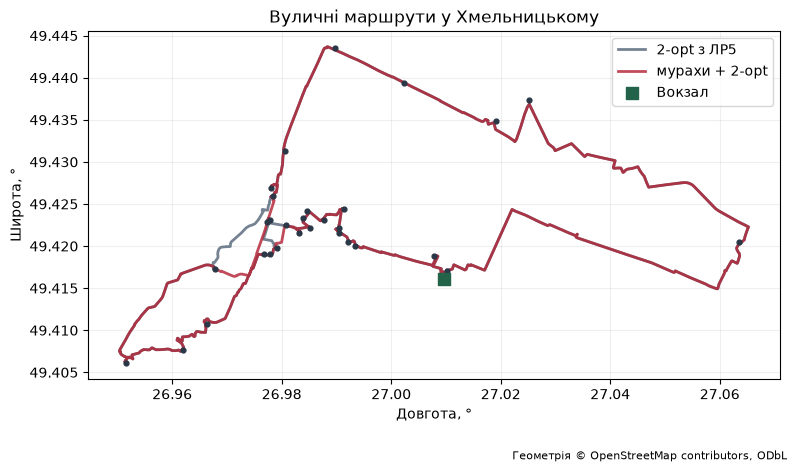

In [21]:
import networkx as nx
import folium
from xyzservices import providers as xyz
from shapely import from_wkb

LAT = np.array([p['lat'] for p in BIG['точки']])
LON = np.array([p['lon'] for p in BIG['точки']])
nodes = pd.read_parquet(NETWORK_DIR/'road_nodes.parquet', columns=['osmid','x','y'])
edges = pd.read_parquet(NETWORK_DIR/'road_edges.parquet', columns=['u','v','length','geometry'])
G = nx.Graph()
G.add_nodes_from((int(r.osmid), {'xy':(float(r.y),float(r.x))}) for r in nodes.itertuples())
for row in edges.itertuples(index=False):
    u,v,length = int(row.u), int(row.v), float(row.length)
    if not G.has_edge(u,v) or length < G[u][v]['length']:
        G.add_edge(u,v,length=length,geometry=row.geometry)
IDS = [int(p['node_id']) for p in BIG['точки']]
pairs = []
for s in IDS:
    lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
    pairs.append([lengths[t] for t in IDS])
worst = float(np.max(np.abs(np.asarray(pairs)-D)))
STREETS = worst < 1.0
assert STREETS, 'Мережа не відповідає матриці ЛР5'
NET = str(NETWORK_DIR.relative_to(HERE.parent))
print(f'{NET}: {G.number_of_nodes()} вузлів, {G.number_of_edges()} ребер. Найбільша розбіжність {worst:.3g} м.')

def route_latlon(genome):
    route = [0, *map(int, genome), 0]
    coords = []
    for a,b in zip(route,route[1:]):
        path = nx.shortest_path(G, IDS[a], IDS[b], weight='length')
        for u,v in zip(path,path[1:]):
            start, end = G.nodes[u]['xy'], G.nodes[v]['xy']
            shape = from_wkb(G[u][v]['geometry'])
            segment = [(y,x) for x,y in shape.coords] if shape is not None and not shape.is_empty else [start,end]
            if math.dist(segment[-1],start) < math.dist(segment[0],start):
                segment.reverse()
            coords.extend(segment if not coords or coords[-1] != segment[0] else segment[1:])
    return coords

best_ga = min(GA, key=lambda r:r['довжина'])
best_aco = min(ACO, key=lambda r:r['довжина'])
layers = [
    (f'ЛР5: 2-opt ({L_2OPT/1000:.2f} км)', OPT2, '#566779', 6, True),
    (f'ГА: найкращий ({best_ga["довжина"]/1000:.2f} км)', best_ga['маршрут'], '#1f67b3', 4, False),
    (f'Мурахи: найкращий ({best_aco["довжина"]/1000:.2f} км)', best_aco['маршрут'], '#d66918', 4, False),
    (f'Найкращий: {BEST_NAME} ({L_BEST/1000:.2f} км)', BEST_TOUR, '#b42336', 4, True),
]
routes = [route_latlon(genome) for _,genome,_,_,_ in layers]
assert all(len(coords)>n for coords in routes)
fmap = folium.Map(location=[float(LAT.mean()),float(LON.mean())], tiles=None, control_scale=True)
folium.TileLayer(xyz.Esri.WorldGrayCanvas, name='Підкладка Esri').add_to(fmap)
for (name, _, color, width, show), coords in zip(layers,routes):
    group = folium.FeatureGroup(name=name,show=show)
    folium.PolyLine(coords,color=color,weight=width,opacity=.82,tooltip=name).add_to(group)
    group.add_to(fmap)
positions_lr5 = {int(g): k for k,g in enumerate(OPT2,1)}
for k,g in enumerate([0,*map(int,BEST_TOUR)]):
    tip = f'{k}. {NAMES[g]} (позиція в ЛР5: {positions_lr5[g]})' if k else NAMES[0]
    icon = folium.DivIcon(html=f'<div style="background:white;border:2px solid #b42336;border-radius:50%;width:23px;height:23px;text-align:center;font:bold 12px/19px sans-serif">{k}</div>')
    folium.Marker([LAT[g],LON[g]],tooltip=tip,icon=icon).add_to(fmap)
fmap.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:45px;left:12px;z-index:9999;background:white;padding:8px 12px;'
    'border-radius:5px;font:13px sans-serif">ЛР8 · Хмельницький · пішохідні маршрути<br>'
    'Червоний: найкращий. Сірий: ЛР5. Геометрія © OpenStreetMap contributors, ODbL.</div>'))
folium.LayerControl(collapsed=False).add_to(fmap)
fmap.fit_bounds([[float(LAT.min()),float(LON.min())],[float(LAT.max()),float(LON.max())]])
MAP_FILE = f'lr8_маршрут_{LIST_NUMBER:02d}.html'
fmap.save(str(HERE/MAP_FILE))
MAP_MD5 = hashlib.md5((HERE/MAP_FILE).read_bytes()).hexdigest()[:10]
print(f'Збережено {MAP_FILE}. Точок геометрії в чотирьох шарах: {[len(v) for v in routes]}.')
display(fmap)

# Статичне зіставлення вуличної геометрії для звіту.
fig, ax = plt.subplots(figsize=(8, 5))
for index in (0,3):
    a = np.asarray(routes[index])
    ax.plot(a[:,1], a[:,0], color=layers[index][2], lw=2, alpha=.82,
            label='2-opt з ЛР5' if index==0 else BEST_NAME)
ax.scatter(LON[1:],LAT[1:],s=12,c='#293747',zorder=3)
ax.scatter(LON[0],LAT[0],s=64,marker='s',c='#23634a',label='Вокзал',zorder=4)
ax.set(aspect=1/np.cos(np.radians(float(LAT.mean()))), xlabel='Довгота, °', ylabel='Широта, °')
ax.legend(loc='best')
ax.grid(alpha=.2)
ax.set_title('Вуличні маршрути у Хмельницькому')
fig.text(.99,.01,'Геометрія © OpenStreetMap contributors, ODbL',ha='right',fontsize=8)
fig.tight_layout(rect=(0,.025,1,1))
plt.show()

**Що видно на карті.** Увімкніть шари «ЛР5» і «найкращий» разом. Знайдіть **2–3 точки**, біля яких найкращий маршрут
іде **інакше**, ніж маршрут ЛР5 (заходить у них з іншої точки або виходить до іншої), і поясніть, що дає цей порядок:
де він виграє у ЛР5 і, якщо найкращий не побив ЛР5, де програє (обхід кварталу, одностороння вулиця, повернення назад тощо). Назви копіюйте з підказок маркерів. Якщо найкращий
маршрут збігся з ЛР5 — залиште список порожнім і напишіть, чому так могло статися.

In [22]:
def arcs(genome):
    route = [0, *map(int, genome), 0]
    return set(zip(route, route[1:]))

old_edges, new_edges = arcs(OPT2), arcs(BEST_TOUR)
removed = sorted(old_edges - new_edges)
added = sorted(new_edges - old_edges)
removed_m = sum(D[a,b] for a,b in removed)
added_m = sum(D[a,b] for a,b in added)
assert np.isclose(removed_m - added_m, L_2OPT - L_BEST, atol=1e-8, rtol=0)

def neighbours(genome):
    route = [0, *map(int, genome)]
    return {g: (route[i-1],route[(i+1)%len(route)]) for i,g in enumerate(route)}

before, after = neighbours(OPT2), neighbours(BEST_TOUR)
# На симетричній матриці простий розворот не змінює географічну пару сусідів.
changed = [i for i in range(1,n) if
           (set(before[i]) != set(after[i]) if asym < 1e-6 else before[i] != after[i])]
def local_gain(i):
    a,b = before[i]
    c,d = after[i]
    return D[a,i]+D[i,b]-D[c,i]-D[i,d]

selected_points = sorted(changed, key=lambda i: (-local_gain(i), i))[:3]
MAP_POINTS = [NAMES[i] for i in selected_points]
def connection(i, pair):
    a,b = pair
    return f'{NAMES[a]} → {NAMES[i]} → {NAMES[b]} ({D[a,i]+D[i,b]:.1f} м)'

MAP_ROWS = [{'Точка':NAMES[i], 'У ЛР5':connection(i,before[i]), 'Новий маршрут':connection(i,after[i])}
            for i in selected_points]
# Для симетричного графа окремо рахуємо географічно змінені зв’язки.
if asym < 1e-6:
    old_links = {tuple(sorted(e)) for e in old_edges}
    new_links = {tuple(sorted(e)) for e in new_edges}
else:
    old_links, new_links = old_edges, new_edges
old_m = sum(D[a,b] for a,b in sorted(old_links-new_links))
new_m = sum(D[a,b] for a,b in sorted(new_links-old_links))
assert np.isclose(old_m-new_m,L_2OPT-L_BEST,atol=1e-8,rtol=0)
MAP_WHY = (f'На карті новий порядок змінює {len(new_links-old_links)} вуличних зв’язків між точками. '
           f'Довжина замінених зв’язків {old_m:.1f} м, нових {new_m:.1f} м, економія {old_m-new_m:.1f} м. '
           'У таблиці показано, через яких сусідів новий маршрут проходить біля вибраних пам’яток. '
           'Локальні різниці за пам’ятками можуть перетинатися, тому економію підраховано за множинами ребер.')
if MAP_ROWS:
    display(pd.DataFrame(MAP_ROWS))
print(MAP_WHY)

,Точка,У ЛР5,Новий маршрут
0,Пам'ятник-фонтан барону Мюнхгаузену,Хмельницький обласний краєзнавчий музей → Пам'...,Хмельницький обласний краєзнавчий музей → Пам'...
1,Пам'ятник Богданові Хмельницькому,Братська могила розстріляних євреїв → Пам'ятни...,Братська могила жертв Проскурівського погрому ...
2,Братська могила жертв Проскурівського погрому,Пам'ятник-фонтан барону Мюнхгаузену → Братська...,ЗіС-5 → Братська могила жертв Проскурівського ...


На карті новий порядок змінює 4 вуличних зв’язків між точками. Довжина замінених зв’язків 3747.7 м, нових 3509.2 м, економія 238.5 м. У таблиці показано, через яких сусідів новий маршрут проходить біля вибраних пам’яток. Локальні різниці за пам’ятками можуть перетинатися, тому економію підраховано за множинами ребер.


In [23]:
_e5 = set(zip([0] + [int(g) for g in OPT2], [int(g) for g in OPT2] + [0]))
_eb = set(zip([0] + [int(g) for g in BEST_TOUR], [int(g) for g in BEST_TOUR] + [0]))
DIFF_NAMES = {NAMES[i] for e in _eb - _e5 for i in e}
assert (HERE / MAP_FILE).is_file(), 'карту не збережено — виконайте попередню комірку'
assert all(p in NAMES for p in MAP_POINTS), 'назви мають точно збігатися з підказками маркерів: %s' % [p for p in MAP_POINTS if p not in NAMES]
if DIFF_NAMES:
    assert 2 <= len(MAP_POINTS) <= 3, 'назвіть 2–3 точки'
    assert all(p in DIFF_NAMES for p in MAP_POINTS), 'біля точок %s маршрути ЛР5 і найкращий ідуть однаково — подивіться на карту ще раз' % [p for p in MAP_POINTS if p not in DIFF_NAMES]
else:
    assert MAP_POINTS == [], 'найкращий маршрут збігся з ЛР5 — список має бути порожнім'
assert len(MAP_WHY) > 40, 'опишіть, що видно на карті'
print('ребер, якими найкращий маршрут відрізняється від ЛР5: %d з %d' % (len(_eb - _e5), n))

ребер, якими найкращий маршрут відрізняється від ЛР5: 7 з 31


---
## 4. Звіт колеги на критику

Колега розв'язав ту саму задачу для іншого міста і написав висновки. Частина тверджень хибні — за методикою або за
змістом. Знайдіть їх (номери) і коротко поясніть, що не так.

1. «Я запустив ГА один раз і отримав 47,9 км проти 51,2 км у 2-opt — отже, ГА кращий за 2-opt на 6 %.»
2. «Мурахам я дав 100 000 оцінок, а ГА — 10 000; мурахи дали коротший маршрут, тож мурахи кращі за ГА.»
3. «Обидва методи запускав по 10 разів з однаковим бюджетом 20 000 оцінок і порівнюю медіани та квартилі.»
4. «Щоб пришвидшити 2-opt, я рахував зміну довжини після розвороту за чотирма ребрами, як у лекції.»
5. «Для близькості η = 1/d я замінив нульові віддалі на нескінченність, щоб не ділити на нуль.»
6. «Після доведення 2-opt маршрут ГА скоротився з 55,4 до 50,1 км; 2-opt коштував ще 1 300 оцінок, і я додав їх до вартості ГА.»
7. «Мурахи дали маршрут на 3 % коротший за 2-opt, тому в мобільному застосунку маршрут треба будувати тільки мурахами.»

In [24]:
WRONG = [1, 2, 4, 5, 7]
WRONG_WHY = {
    1: 'Один запуск показує лише один випадковий результат. Для висновку про типовий виграш треба повторити ГА з різними сідами й порівняти медіану та розкид із 2-opt.',
    2: 'Мурахи отримали вдесятеро більший бюджет. Перевагу методу слід оцінити на однаковій кількості обчислень довжини й окремо зіставити час.',
    4: 'На несиметричній матриці розворот міняє напрям усіх внутрішніх дуг сегмента. Формула за чотирма граничними ребрами працює лише для симетричного випадку.',
    5: 'Заміна нульової віддалі нескінченністю дає нульову близькість для фактично сусідньої точки. Нижня межа 1 м зберігає великий скінченний пріоритет.',
    7: 'Для мобільного застосунку важливі час відповіді та вартість. Треба виміряти, чи варта економія 3% додаткової затримки для задачі.',
}
print('Твердження 3 дотримується рівних бюджетів і повторів. Твердження 6 враховує додаткову вартість гібрида.')

Твердження 3 дотримується рівних бюджетів і повторів. Твердження 6 враховує додаткову вартість гібрида.


In [25]:
assert WRONG and all(isinstance(k, int) and 1 <= k <= 7 for k in WRONG), 'вкажіть номери хибних тверджень від 1 до 7'
assert all(k in WRONG_WHY and len(str(WRONG_WHY[k])) > 15 for k in WRONG), 'поясніть кожне хибне твердження (не одним словом)'

---
## 5. Звіт

Відповідайте **числами з ваших виводів**. Останнє питання — головне для оцінки: за яких умов доцільний кожен метод.

In [26]:
def median(runs, key):
    return float(np.median([r[key] for r in runs]))

ga_l, aco_l = median(GA, 'довжина'), median(ACO, 'довжина')
ga_t, aco_t = median(GA, 'час_с'), median(ACO, 'час_с')
def compare_to_baseline(value):
    gap = 100 * (value / L_2OPT - 1)
    return f'{value:.1f} м проти {L_2OPT:.1f} м (відносна зміна {gap:+.2f}%)'

winner = 'мурашина система' if aco_l < ga_l else 'генетичний алгоритм' if ga_l < aco_l else 'медіани однакові'
significance = 'різниця значуща на рівні 0,05' if P_GA_ACO < 0.05 else 'на рівні 0,05 різницю не підтверджено'
hyb_details = ' '.join(f"{k}: {v['до 2-opt, м']:.1f} → {v['після 2-opt, м']:.1f} м, "
                       f"ще {v['додатково оцінок']} оцінок і {v['додатково, с']:.4f} с."
                       for k,v in HYB.items())
REPORT = {
    'q1_ga_vs_lr5': f'Медіана ГА: {compare_to_baseline(ga_l)}. Упорядковане схрещування комбінує порядки обходу, а пошук обмежений бюджетом і не гарантує покращення сильного локального базису.',
    'q2_aco_vs_lr5': f'Медіана мурашиної системи: {compare_to_baseline(aco_l)}. Близькість віддає перевагу коротким переходам, а феромон підсилює дуги в коротких повних турах.',
    'q3_cost': f'2-opt: {EVALS_2OPT} оцінок і {t_2opt:.6f} с після найближчого сусіда. ГА: {BUDGET} оцінок, {ga_t:.4f} с (×{ga_t/t_2opt:.1f}). Мурахи: {BUDGET} оцінок, {aco_t:.4f} с (×{aco_t/t_2opt:.1f}). Підбір параметрів і відбір найкращого з 10 запусків — окремі витрати.',
    'q4_ga_vs_aco': f'За медіаною: {winner}, {ga_l:.1f} м у ГА та {aco_l:.1f} м у мурах. Двобічний тест Манна — Вітні: p={P_GA_ACO:.6g}, {significance}. Це висновок для цих запусків і цієї матриці.',
    'q5_hybrid': f'{hyb_details} Найкращий загалом — {BEST_NAME}, {L_BEST:.1f} м. Економія щодо ЛР5 {L_2OPT-L_BEST:.1f} м ({100*(1-L_BEST/L_2OPT):.2f}%). Для найкращого з 10 запусків кожного методу потрібні {RUNS*BUDGET:,} оцінок плюс доведення, без урахування пілотів.',
    'q6_params': f"ГА: 50 особин, турнір 2, еліта 2, схрещування 0,9, мутація {GA_PARAMS['pm']:.1f}. Медіани пілоту для 0,1 і 0,3: {GA_PILOT[.1]:.1f} і {GA_PILOT[.3]:.1f} м. Мурахи: {n} мураха, α=1, β={ACO_PARAMS['beta']:g}, ρ=0,5. Для β=0 та β=2 медіани {ACO_PILOT[0.0]:.1f} і {ACO_PILOT[2.0]:.1f} м. При β=0 локальна відстань не впливає на вибір, діє лише феромон. Інші параметри взято з базових рекомендацій.",
    'q7_asymmetry': f'У цій ЛР5 граф неорієнтований, асиметрія {asym:.3g} м. Загалом у напрямленій матриці при розвороті змінюються всі внутрішні дуги, і їхні зворотні вартості можуть бути іншими. Код рахує повну довжину й працює в обох випадках.',
    'q8_when': '2-opt підходить для швидкої інтерактивної відповіді та доведення готового маршруту, але може застрягти в локальному мінімумі. ГА доречний для пошуку між різними порядками, коли допустимі повтори й більший бюджет. Мурашина система доречна, коли близькість інформативна й важлива коротка відповідь маршруту за достатнього часу розрахунку. Гібрид доречний для офлайн-планування, коли варто доплатити за пошук і локальне доведення. Для великих задач бюджет і масштабування треба перевірити окремо.'
}
for i, answer in enumerate(REPORT.values(), 1):
    print(f'{i}. {answer}')

1. Медіана ГА: 27613.8 м проти 27249.3 м (відносна зміна +1.34%). Упорядковане схрещування комбінує порядки обходу, а пошук обмежений бюджетом і не гарантує покращення сильного локального базису.
2. Медіана мурашиної системи: 28572.5 м проти 27249.3 м (відносна зміна +4.86%). Близькість віддає перевагу коротким переходам, а феромон підсилює дуги в коротких повних турах.
3. 2-opt: 3046 оцінок і 0.036172 с після найближчого сусіда. ГА: 20000 оцінок, 1.5468 с (×42.8). Мурахи: 20000 оцінок, 22.6166 с (×625.3). Підбір параметрів і відбір найкращого з 10 запусків — окремі витрати.
4. За медіаною: генетичний алгоритм, 27613.8 м у ГА та 28572.5 м у мурах. Двобічний тест Манна — Вітні: p=0.0639221, на рівні 0,05 різницю не підтверджено. Це висновок для цих запусків і цієї матриці.
5. ГА + 2-opt: 27266.6 → 27010.8 м, ще 1306 оцінок і 0.0122 с. мурахи + 2-opt: 27387.2 → 27010.8 м, ще 1306 оцінок і 0.0176 с. Найкращий загалом — мурахи + 2-opt, 27010.8 м. Економія щодо ЛР5 238.5 м (0.88%). Для найк

In [27]:
assert all(len(str(v)) > 15 for v in REPORT.values()), 'дайте відповідь на кожне питання звіту'

---
## 6. Декларація про використання штучного інтелекту — обов'язкова

Користуватися ШІ-асистентами (ChatGPT, Claude, Gemini, Copilot тощо) **дозволено**. Не дозволено видавати
згенероване за своє і здавати код, якого ви не можете пояснити: на захисті викладач попросить пояснити будь-який рядок
ваших чотирьох функцій. **Без заповненої декларації робота не приймається.**

Якщо ШІ не використовували — `'використовував': False`, а в інших полях напишіть `'—'`. Якщо використовували —
назвіть інструмент, для чого саме (пояснення теорії, налагодження, написання функції, текст звіту…), 1–3 головні запити
і **як ви перевірили** відповідь ШІ (тести, власний приклад на папері, порівняння з лекцією).

Декларацію заповнив і підтвердив студент.

In [ ]:
# ----- ВАШІ ВІДПОВІДІ -----
AI_DECLARATION = {
    'використовував': True,     # True / False
    'інструменти': 'Codex',          # напр. 'ChatGPT (GPT-5), Copilot у VS Code' або '—'
    'для_чого': 'код, пояснення, текст звіту',             # які частини роботи: пояснення, налагодження, функції (які саме), текст звіту
    'запити': 'напиши код для ноутбука; поясни мені причинно наслідкові зв\'язки',               # 1–3 головні запити дослівно або близько до тексту
    'як_перевірив': 'обдумував кожне рішення відносно завдання та моїх знань',         # як переконалися, що відповідь ШІ правильна
    'підтверджую': True,       # True: декларація правдива, і я можу пояснити кожен рядок своїх функцій
}
# ----- КІНЕЦЬ -----

In [29]:
assert set(AI_DECLARATION) == {'використовував', 'інструменти', 'для_чого', 'запити', 'як_перевірив', 'підтверджую'}
DECLARATION_COMPLETE = AI_DECLARATION['підтверджую'] is True
if DECLARATION_COMPLETE:
    assert type(AI_DECLARATION['використовував']) is bool
    if AI_DECLARATION['використовував']:
        assert str(AI_DECLARATION['інструменти']).strip()
        assert all(len(str(AI_DECLARATION[k]).strip()) >= 10
                   for k in ('для_чого', 'запити', 'як_перевірив'))
    print('Декларацію заповнено.')
else:
    print('Декларація очікує на особисте заповнення та підтвердження. Розрахунки й JSON доступні.')

Декларацію заповнено.


## Результат

In [30]:
def runs_out(runs):
    return [{'довжина': round(r['довжина'], 1), 'час_с': round(r['час_с'], 4), 'оцінок': r['оцінок']} for r in runs]
def src(fn):
    try:
        return inspect.getsource(fn)
    except Exception:
        return ''
result = {
    'студент': STUDENT_NAME, 'номер': LIST_NUMBER, 'місто': LR5.get('місто'), 'дані': SOURCE, 'матриця_md5': D_MD5, 'точок': n,
    'матриця_віддалей_м': raw,
    'лр5': {'найближчий_сусід_м': BIG['найближчий_сусід_м'], 'двоопт_м': BIG['двоопт_м'], 'двоопт_с': BIG.get('двоопт_с')},
    'відтворено': {'найближчий_сусід_м': round(L_NN, 1), 'двоопт_м': round(L_2OPT, 1), 'двоопт_оцінок': EVALS_2OPT, 'двоопт_с': round(t_2opt, 4), 'збігається': bool(LR5_OK)},
    'бюджет': BUDGET, 'запусків': RUNS, 'ga_params': GA_PARAMS, 'aco_params': {k: (float(v) if k != 'ants' else int(v)) for k, v in ACO_PARAMS.items()},
    'ga': runs_out(GA), 'aco': runs_out(ACO), 'p_ga_aco': P_GA_ACO,
    'гібрид': {k: {kk: (vv.tolist() if kk == 'маршрут' else vv) for kk, vv in v.items()} for k, v in HYB.items()},
    'найкращий_маршрут': [int(i) for i in BEST_TOUR], 'краще_за_лр5': bool(BEAT_LR5),
    'лр5_маршрут': [int(i) for i in OPT2], 'назви': NAMES,
    'карта': {'файл': MAP_FILE, 'md5': MAP_MD5, 'вулицями': bool(STREETS), 'мережа': NET, 'точки': list(MAP_POINTS), 'пояснення': MAP_WHY},
    'тести': {'ga': bool(globals().get('GA_TESTS_OK')), 'aco': bool(globals().get('ACO_TESTS_OK'))},
    'код_студента': {f.__name__: src(f) for f in (tournament, ox, choose_next, update_pheromone)},
    'хибні_твердження': sorted(WRONG), 'пояснення': {str(k): v for k, v in WRONG_WHY.items()},
    'звіт': REPORT, 'декларація_ші': AI_DECLARATION,
    'версії': {'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__, 'folium': folium.__version__, 'networkx': nx.__version__},
}
OUT = 'lr8_результат_%02d.json' % LIST_NUMBER
result['карта']['розбіжність_мережі_м'] = worst
result['карта']['локальні_зв’язки'] = MAP_ROWS
result['підсумкова_таблиця'] = TABLE.reset_index().to_dict('records')
result['декларація_завершена'] = DECLARATION_COMPLETE
result['асиметрія_м'] = asym
assert all(result['код_студента'].values())
with (HERE / OUT).open('w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=2, allow_nan=False)
print('збережено', OUT)
print('здаєте: ноутбук, %s і %s' % (OUT, MAP_FILE))

збережено lr8_результат_12.json
здаєте: ноутбук, lr8_результат_12.json і lr8_маршрут_12.html
